# Heart Disease Prediction – Paper Reproduction
**DS 301 – Mid-Term Project (CICCC)**

**Team:** Felipe Kuerten Neves, Karina Adorno, Carlos Alvarez

---

## 1. Introduction

### The paper
**Aldila, A. S., & Supriyono, L. A. (2026).** *Evaluating Logistic Regression, SVM, KNN, and Ensemble Models for Accurate Heart Disease Risk Prediction.* JITK, 11(3), 949–957. DOI: [10.33480/jitk.v11i3.6738](https://doi.org/10.33480/jitk.v11i3.6738) (open access, CC BY-NC 4.0)

### The problem
Cardiovascular disease is the leading cause of death in the world. Detecting patients at risk early can save lives. The paper uses machine learning to predict **whether a patient has heart disease or not** (binary classification), using clinical data such as age, chest pain type, cholesterol and maximum heart rate.

The paper compares six models (Logistic Regression, SVM, KNN, Decision Tree, Random Forest and Gradient Boosting). It reports that **KNN had the highest accuracy (88.52%)** and Random Forest and SVM the highest AUC (0.93).

### The dataset
**Cleveland Heart Disease dataset** – UCI Machine Learning Repository (303 patients, 13 features + 1 target).

Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1989). Heart Disease [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X (CC BY 4.0)

### Objective of this notebook
1. **Reproduce** the paper's steps for the models taught in class: **Logistic Regression, KNN, SVM and Decision Tree**. Random Forest and Gradient Boosting were not covered in class yet, so they were not implemented.
2. **Compare** our results with the paper's results.
3. **Improve** the models with hyperparameter tuning and **suggest** further improvements.

### Team agreement
- Target: binary (0 = No Disease, 1 = Heart Disease)
- 80/20 stratified train/test split, `random_state = 42`
- Stratified cross-validation for hyperparameter tuning
- Primary metric: **Recall** (to minimize false negatives: patients with heart disease classified as healthy). Accuracy, precision, specificity, F1-score and ROC-AUC are also reported.

### Notebook structure
| # | Section |
|---|---|
| 2 | Setup and configuration |
| 3 | Data loading and dataset description |
| 4 | Data quality and cleaning |
| 5 | Exploratory Data Analysis (EDA) |
| 6 | Train/test split |
| 7 | Preprocessing pipeline (encoding + Min-Max scaling) |
| 8 | Paper reproduction (paper's hyperparameters) |
| 9 | Why the paper's SVM fails |
| 10 | Hyperparameter tuning (GridSearchCV) |
| 11 | Final evaluation on the test set |
| 12 | Decision Tree interpretation |
| 13 | Comparison with the paper |
| 14 | Issues found in the paper |
| 15 | Suggested improvements |
| 16 | Conclusions and limitations |

## 2. Setup and Configuration

All the project settings are defined in one place, so the team can change them easily.

- `N_FOLDS = 6` follows the paper (*"six-fold cross-validation"*). **Note:** the initial team agreement said 5-fold; we changed to 6-fold to match the paper's methodology.
- `TUNING_METRIC = "recall"` follows the team agreement (primary metric).

> **Reproducibility note:** the results written in the markdown tables were obtained with the library versions printed below. Other versions of scikit-learn may give slightly different numbers; if so, the code outputs are the reference.

In [1]:
# Install the UCI dataset loader (already available in most environments after this line)
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

from sklearn.exceptions import UndefinedMetricWarning

# FutureWarning: version notices; UndefinedMetricWarning: appears when a model
# predicts no positives in a fold (the paper's SVM) - precision is then set to 0
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

# ---- Project configuration (team agreement) ----
RANDOM_STATE = 42          # reproducible split and cross-validation
TEST_SIZE = 0.20           # 80/20 split
N_FOLDS = 6                # six-fold cross-validation, as in the paper
TUNING_METRIC = "recall"   # primary metric used to select hyperparameters
SCALE_RANGE = (0, 10)      # Min-Max range described in the paper

import sklearn
print("pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
print("Setup complete!")

pandas: 3.0.5 | scikit-learn: 1.9.1
Setup complete!


## 3. Data Loading and Dataset Description

The dataset is downloaded directly from the UCI repository with `ucimlrepo`, so **no manual upload is needed**. If UCI is not reachable, the same file (`processed.cleveland.data`) is loaded from the team's GitHub repository.

> We use the **processed Cleveland file (14 attributes)**. The raw `cleveland.data` file is reported as corrupted in the dataset's WARNING note (David Aha, UCI), so it was not used.

In [3]:
COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

GITHUB_URL = ("https://raw.githubusercontent.com/karinaadorno93-sudo/"
              "Midterm-Project/main/processed.cleveland.data")

try:
    from ucimlrepo import fetch_ucirepo
    heart = fetch_ucirepo(id=45)
    df = pd.concat([heart.data.features, heart.data.targets], axis=1)[COLUMNS]
    source = "UCI repository (ucimlrepo, id = 45)"
except Exception:
    # Fallback: same file from the team's GitHub repo ("?" marks missing values)
    df = pd.read_csv(GITHUB_URL, header=None, names=COLUMNS, na_values="?")
    source = "team GitHub repository (processed.cleveland.data)"

print("Data source:", source)
print("Shape:", df.shape)
df.head()

Data source: team GitHub repository (processed.cleveland.data)
Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### 3.1 Dataset Description

| # | Feature | Description | Type |
|---|---|---|---|
| 1 | `age` | Age in years | Numerical |
| 2 | `sex` | 0 = female, 1 = male | Binary |
| 3 | `cp` | Chest pain type (1: typical angina, 2: atypical angina, 3: non-anginal pain, 4: asymptomatic) | Categorical |
| 4 | `trestbps` | Resting blood pressure (mm Hg) | Numerical |
| 5 | `chol` | Serum cholesterol (mg/dl) | Numerical |
| 6 | `fbs` | Fasting blood sugar > 120 mg/dl (0 = false, 1 = true) | Binary |
| 7 | `restecg` | Resting ECG (0: normal, 1: ST-T wave abnormality, 2: left ventricular hypertrophy) | Categorical |
| 8 | `thalach` | Maximum heart rate achieved (bpm) | Numerical |
| 9 | `exang` | Exercise-induced angina (0 = no, 1 = yes) | Binary |
| 10 | `oldpeak` | ST depression induced by exercise relative to rest | Numerical |
| 11 | `slope` | Slope of the peak exercise ST segment (1: upsloping, 2: flat, 3: downsloping) | Categorical |
| 12 | `ca` | Number of major vessels colored by fluoroscopy (0–3) | Numerical (discrete) |
| 13 | `thal` | Thalassemia (3: normal, 6: fixed defect, 7: reversible defect) | Categorical |
| 14 | `num` → `target` | Diagnosis: originally 0–4, converted to **0 = No Disease, 1 = Heart Disease** | Target |

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


## 4. Data Quality and Cleaning

### 4.1 Missing values and duplicates

In [5]:
missing = pd.DataFrame({
    "Missing values": df.isnull().sum(),
    "Missing (%)": (df.isnull().mean() * 100).round(2)
})
display(missing[missing["Missing values"] > 0])

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nRows with missing values:")
display(df[df.isnull().any(axis=1)])

,Missing values,Missing (%)
ca,4,1.32
thal,2,0.66


Total missing values: 6
Duplicate rows: 0

Rows with missing values:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,2
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0


### 4.2 Cleaning (following the paper)

- **Missing values:** the paper **removes** the rows with missing values in `ca` and `thal`. They are only 6 rows (2% of the data), and imputing clinical values could distort the data.
- **Target:** the original `num` column goes from 0 to 4 (0 = no disease, 1–4 = different degrees of disease). As in the paper, it is converted to **binary**: 0 = No Disease, 1 = Heart Disease.

In [6]:
df_clean = df.dropna(subset=["ca", "thal"]).copy()
df_clean["target"] = (df_clean["num"] > 0).astype(int)
df_clean = df_clean.drop(columns="num").reset_index(drop=True)

print("Rows before cleaning:", len(df))
print("Rows after cleaning: ", len(df_clean))
print("Rows removed:        ", len(df) - len(df_clean))
print("Remaining missing values:", df_clean.isnull().sum().sum())

target_summary = pd.DataFrame({
    "Patients": df_clean["target"].value_counts().sort_index(),
    "Percentage (%)": (df_clean["target"].value_counts(normalize=True).sort_index() * 100).round(2)
}).rename(index={0: "0 - No Disease", 1: "1 - Heart Disease"})
display(target_summary)

Rows before cleaning: 303
Rows after cleaning:  297
Rows removed:         6
Remaining missing values: 0


,Patients,Percentage (%)
target,,
0 - No Disease,160,53.87
1 - Heart Disease,137,46.13


## 5. Exploratory Data Analysis (EDA)

The EDA describes the 297 patients after cleaning. It is descriptive only: nothing here is used to fit the models.

In [7]:
NUMERICAL = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
CATEGORICAL = ["cp", "restecg", "slope", "thal"]
BINARY = ["sex", "fbs", "exang"]

print("Numerical features - descriptive statistics:")
display(df_clean[NUMERICAL].describe().round(2).T)

Numerical features - descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
age,297.0,54.54,9.05,29.0,48.0,56.0,61.0,77.0
trestbps,297.0,131.69,17.76,94.0,120.0,130.0,140.0,200.0
chol,297.0,247.35,52.00,126.0,211.0,243.0,276.0,564.0
thalach,297.0,149.60,22.94,71.0,133.0,153.0,166.0,202.0
oldpeak,297.0,1.06,1.17,0.0,0.0,0.8,1.6,6.2
ca,297.0,0.68,0.94,0.0,0.0,0.0,1.0,3.0


### 5.1 Target distribution

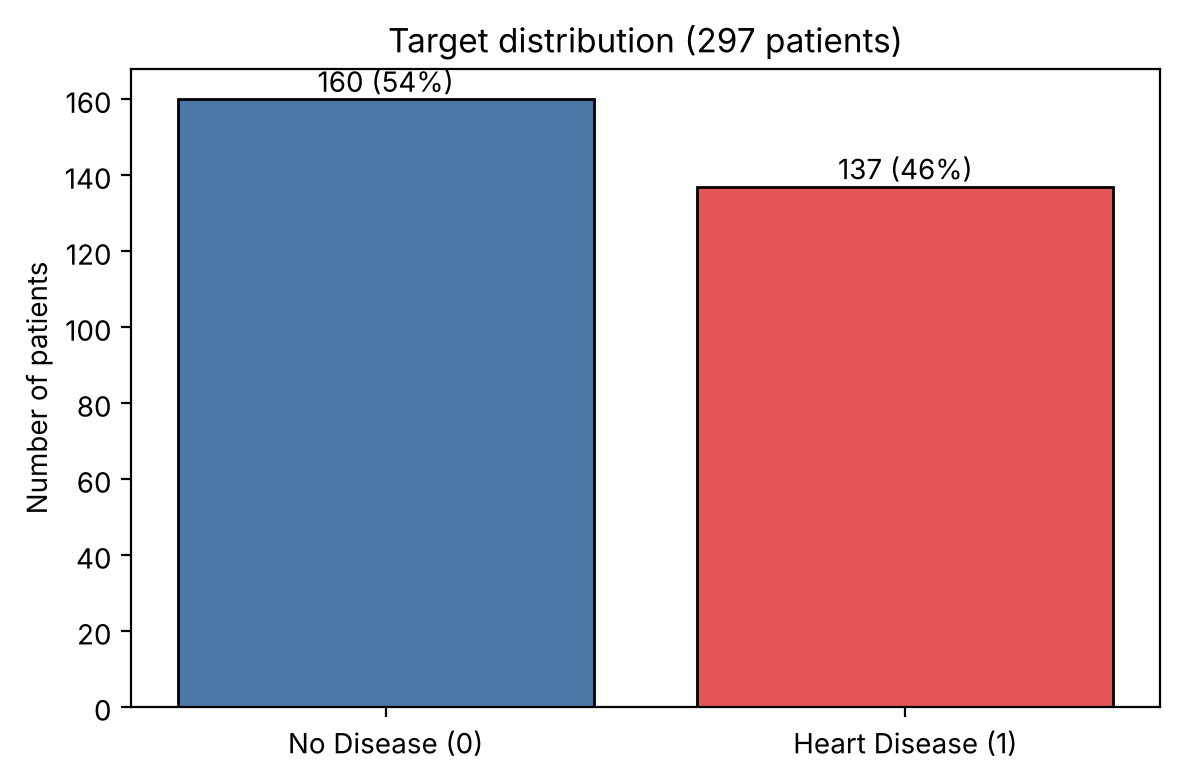

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
counts = df_clean["target"].value_counts().sort_index()
ax.bar(["No Disease (0)", "Heart Disease (1)"], counts.values,
       color=["#4C78A8", "#E45756"], edgecolor="black")
for i, v in enumerate(counts.values):
    ax.text(i, v + 2, f"{v} ({v / len(df_clean):.0%})", ha="center")
ax.set_title("Target distribution (297 patients)")
ax.set_ylabel("Number of patients")
plt.tight_layout()
plt.show()

### 5.2 Numerical features: distributions and outliers

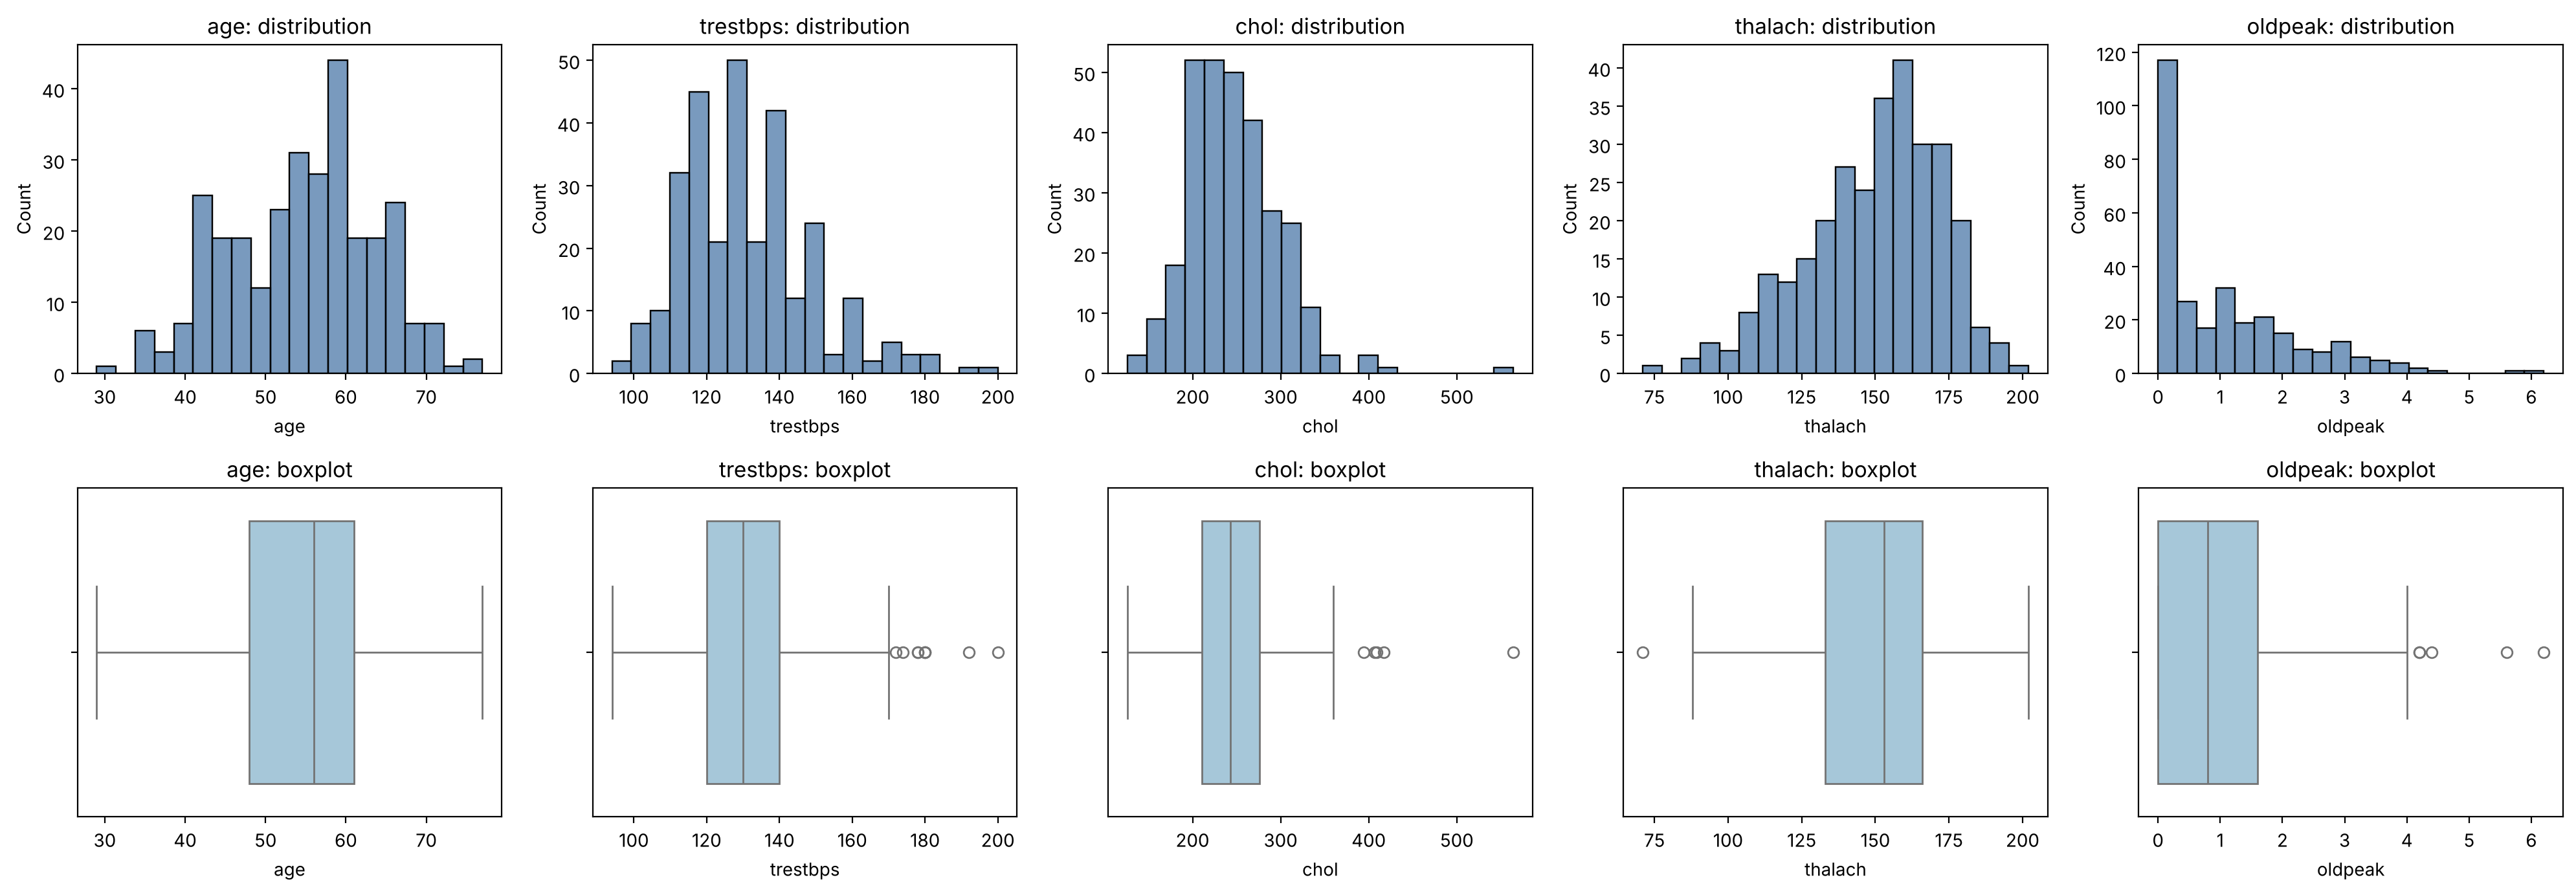

Outliers per feature (IQR rule):
age         0
trestbps    9
chol        5
thalach     1
oldpeak     5
dtype: int64


In [9]:
continuous = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(2, len(continuous), figsize=(20, 7))
for i, col in enumerate(continuous):
    sns.histplot(data=df_clean, x=col, bins=20, ax=axes[0, i], color="#4C78A8")
    axes[0, i].set_title(f"{col}: distribution")
    sns.boxplot(data=df_clean, x=col, ax=axes[1, i], color="#9ecae1")
    axes[1, i].set_title(f"{col}: boxplot")
plt.tight_layout()
plt.show()

# Outliers with the IQR rule (they are kept, as in the paper)
Q1 = df_clean[continuous].quantile(0.25)
Q3 = df_clean[continuous].quantile(0.75)
IQR = Q3 - Q1
outliers = ((df_clean[continuous] < Q1 - 1.5 * IQR) |
            (df_clean[continuous] > Q3 + 1.5 * IQR)).sum()
print("Outliers per feature (IQR rule):")
print(outliers)

### 5.3 Categorical and binary features

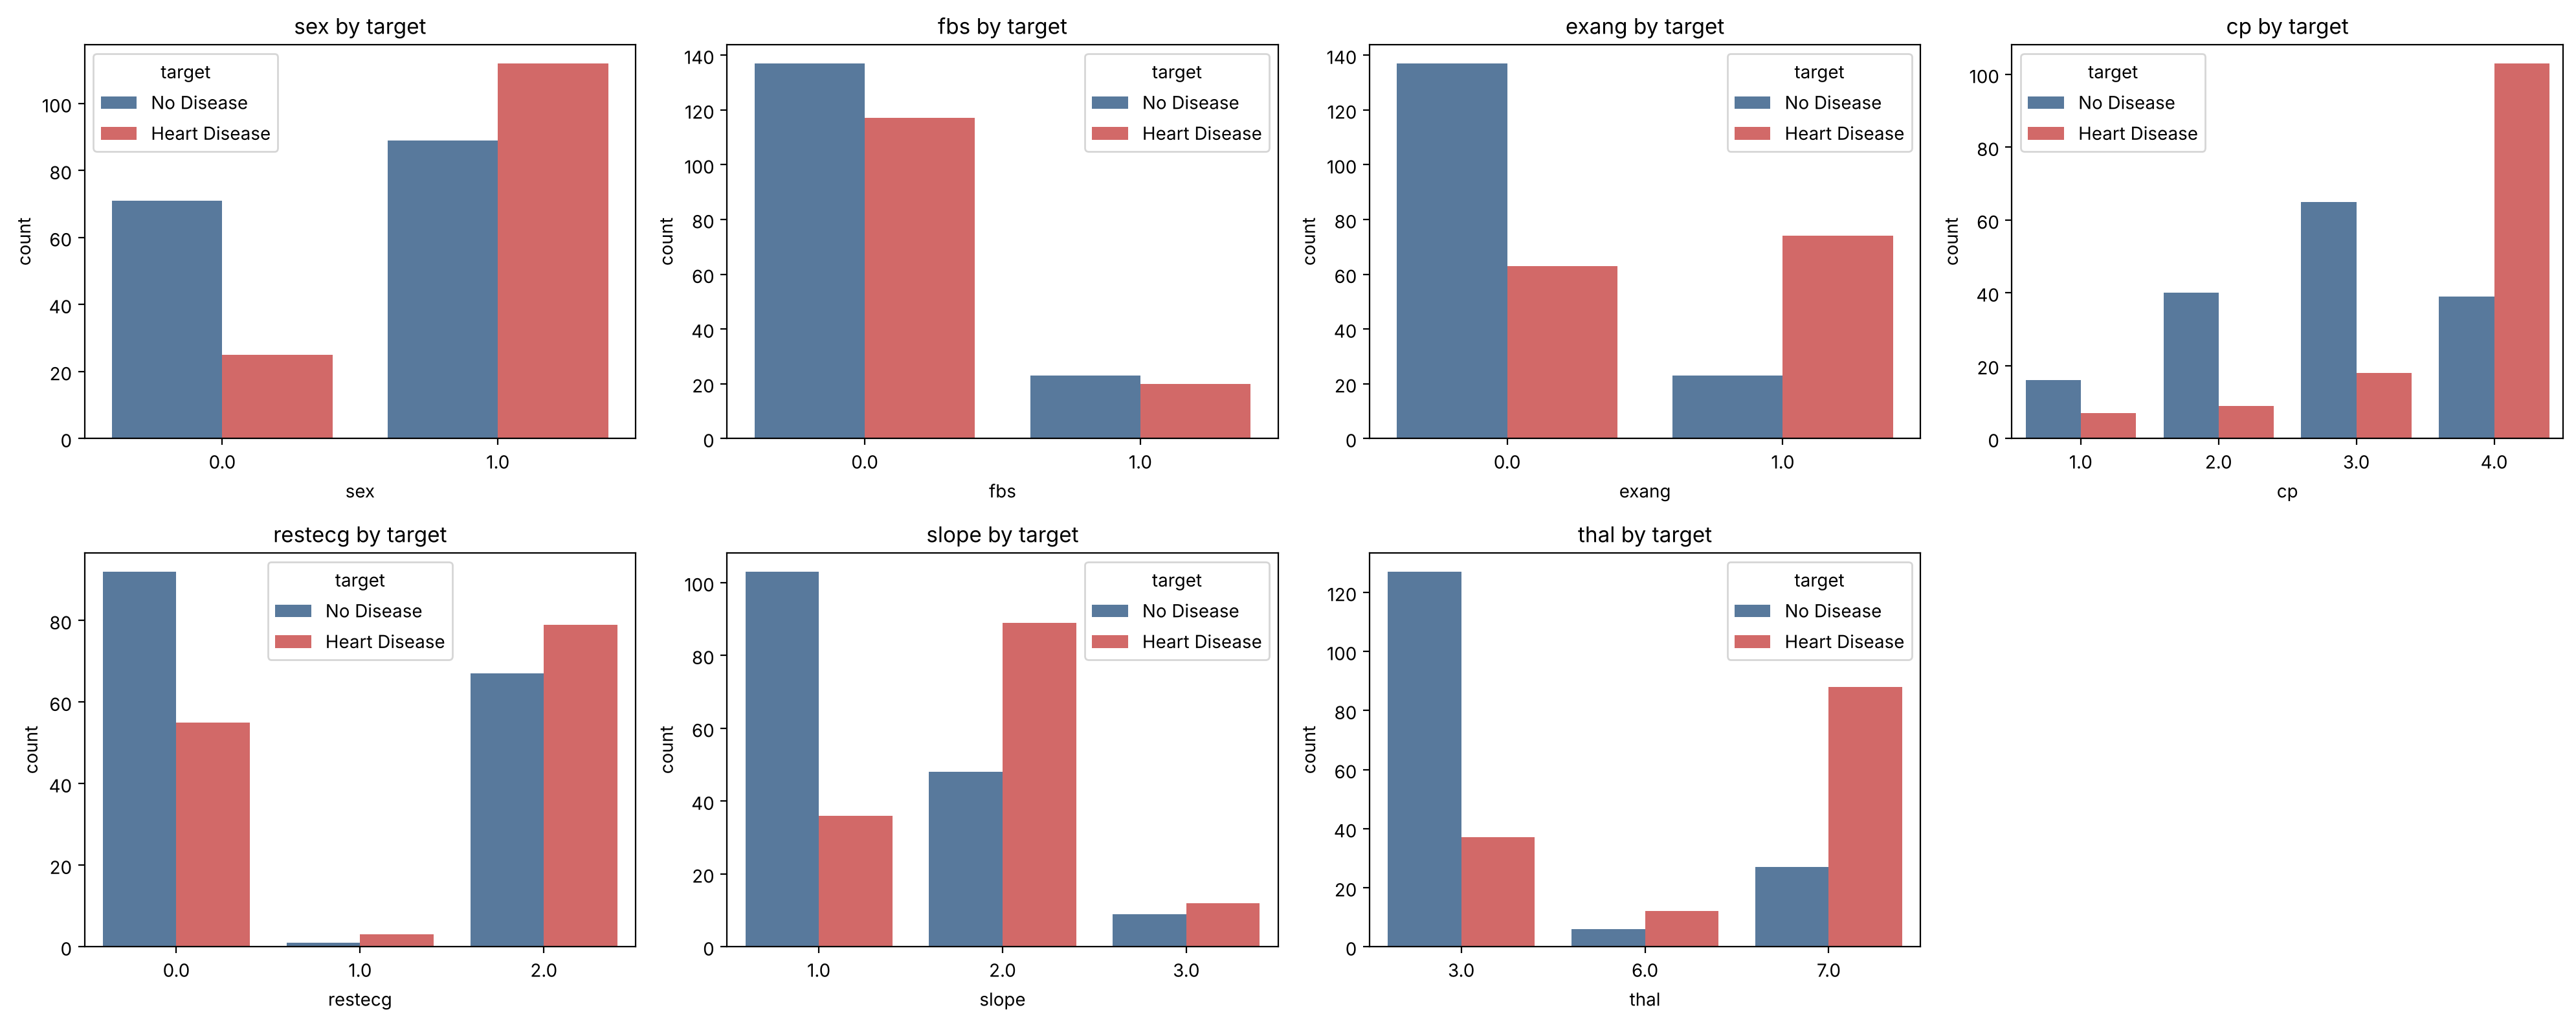

In [10]:
cat_cols = BINARY + CATEGORICAL
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flat, cat_cols):
    sns.countplot(data=df_clean, x=col, hue="target", ax=ax,
                  palette=["#4C78A8", "#E45756"])
    ax.set_title(f"{col} by target")
    ax.legend(title="target", labels=["No Disease", "Heart Disease"])
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

### 5.4 Correlation analysis

Pearson correlation is used to explore linear relationships. Correlations involving categorical features coded as numbers should be interpreted with care.

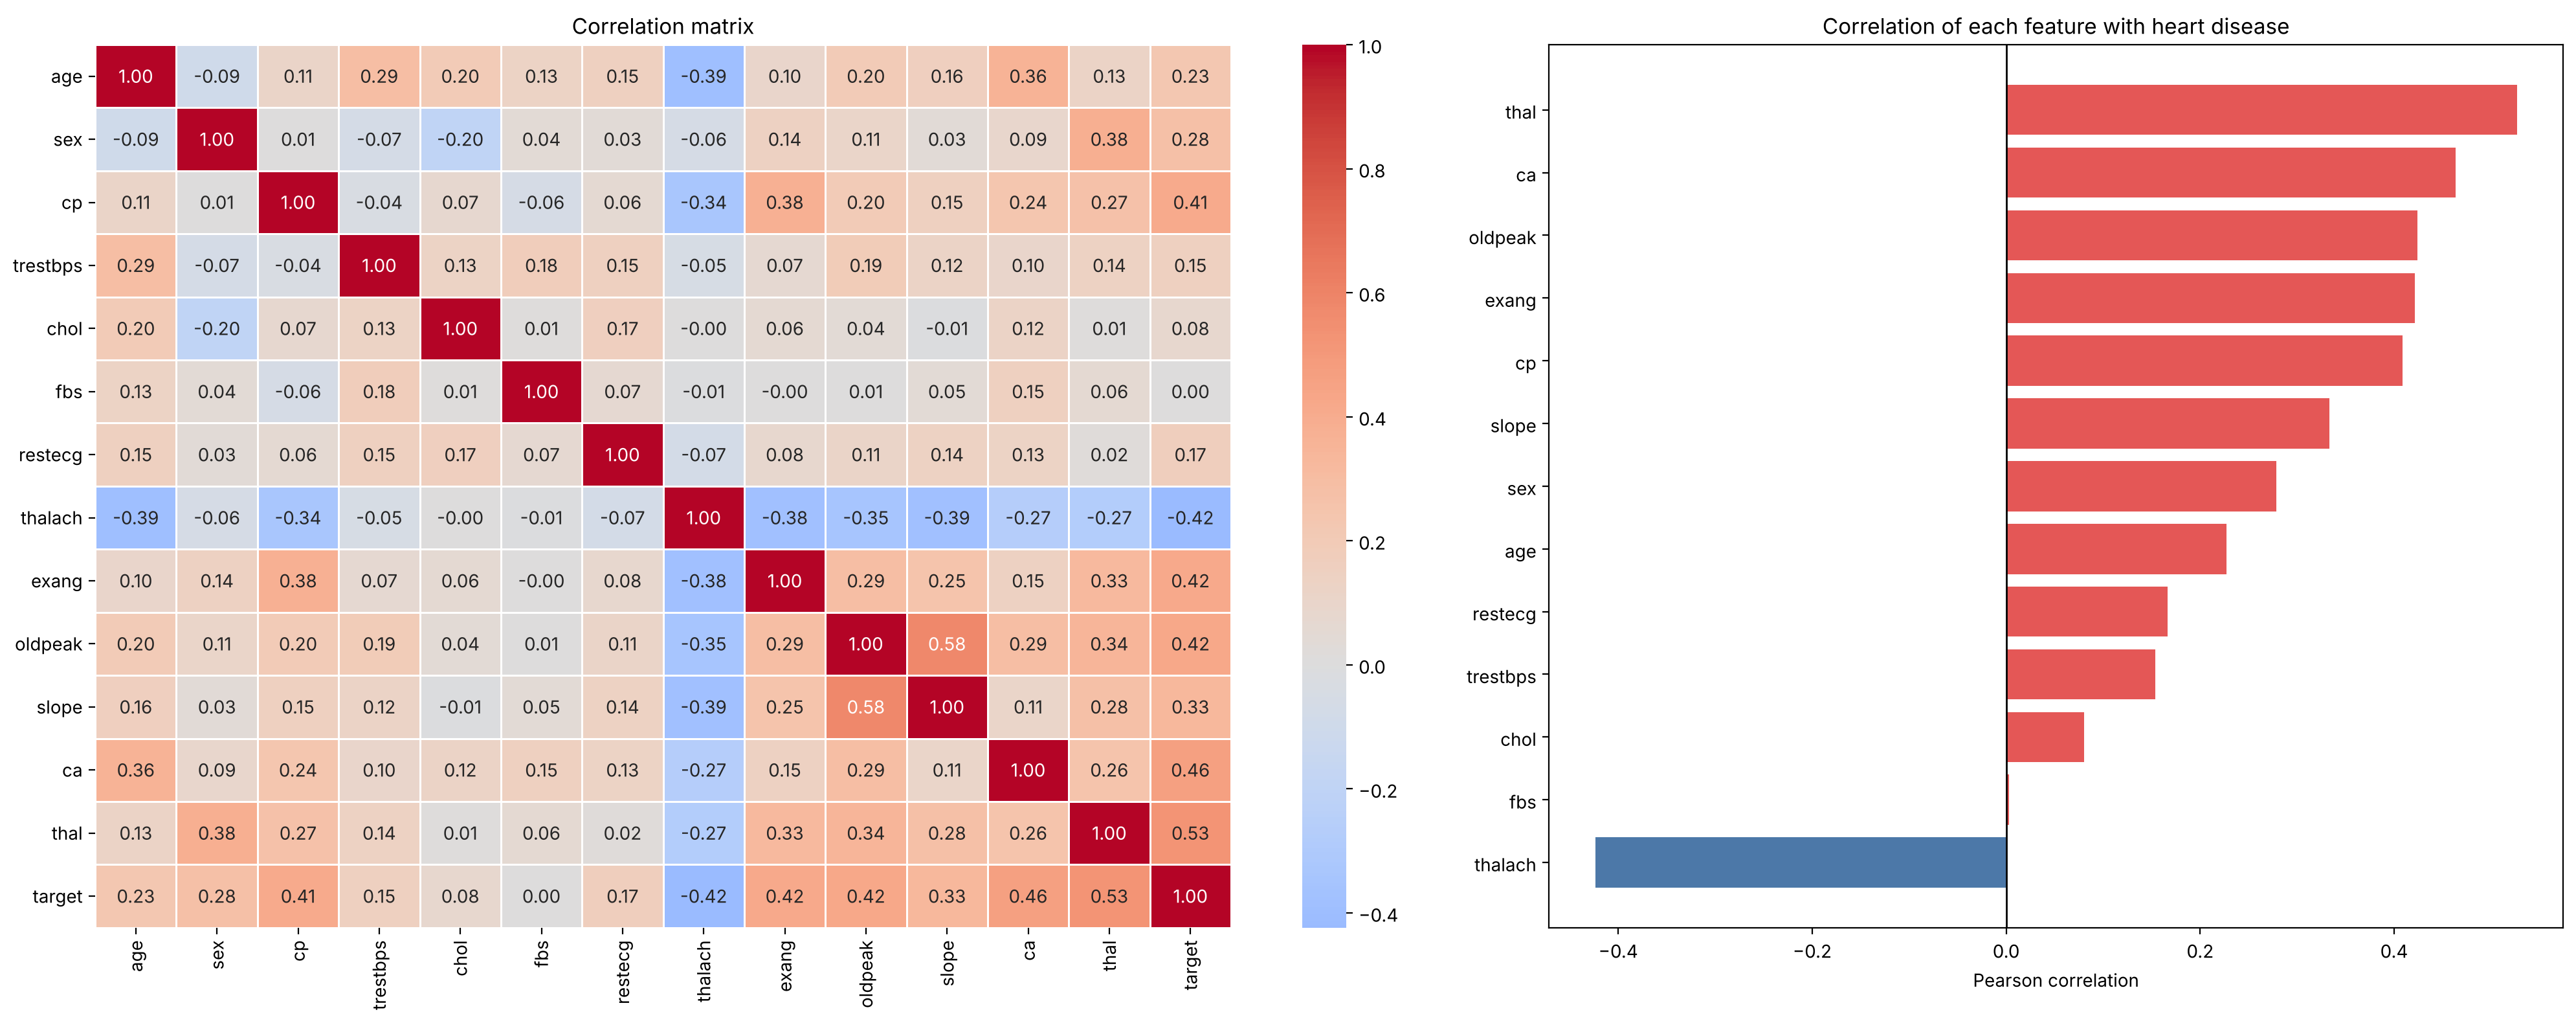

thal        0.527
ca          0.463
oldpeak     0.424
exang       0.421
cp          0.409
slope       0.333
sex         0.278
age         0.227
restecg     0.166
trestbps    0.153
chol        0.080
fbs         0.003
thalach    -0.424
dtype: float64


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={"width_ratios": [1.4, 1]})

sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5, ax=axes[0])
axes[0].set_title("Correlation matrix")

target_corr = df_clean.drop(columns="target").corrwith(df_clean["target"]).sort_values()
axes[1].barh(target_corr.index, target_corr.values,
             color=["#E45756" if v > 0 else "#4C78A8" for v in target_corr.values])
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Correlation of each feature with heart disease")
axes[1].set_xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

print(target_corr.sort_values(ascending=False).round(3))

### 5.5 EDA findings
- **Target:** 160 patients without heart disease (54%) and 137 with heart disease (46%). The classes are **well balanced**, so no resampling is needed.
- **Sex:** the dataset is mostly male (about 68%). This is a limitation: the models may not generalize equally well to women.
- **Outliers:** the IQR rule finds a few outliers in `trestbps` (9), `chol` (5), `oldpeak` (5) and `thalach` (1). As in the paper, **all patients were kept**, because these values are clinically possible and the dataset is small.
- **Strongest relationships with heart disease:** `thal` (+0.53), `ca` (+0.46), `oldpeak` (+0.42), `exang` (+0.42), `cp` (+0.41) and `thalach` (−0.42, a lower maximum heart rate is linked to disease). `chol` and `fbs` have almost no linear relationship with the target.
- **Categorical patterns:** most patients with *asymptomatic* chest pain (`cp` = 4) and with a *reversible defect* (`thal` = 7) have heart disease.
- No pair of features is extremely correlated (the highest is `oldpeak`–`slope`, 0.58), so all 13 features are kept, as in the paper.

## 6. Train/Test Split

- **80/20 split**, as in the paper.
- **Stratified with `random_state = 42`** (team agreement): keeps the same class proportion in train and test, and makes the results reproducible. The paper does not mention stratification or its `random_state`.
- The test set is **never used to choose models or hyperparameters**. It is used only for evaluation: once for the paper's models (Section 8) and once for the tuned models (Section 11).

In [12]:
X = df_clean.drop(columns="target")
y = df_clean["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
display(pd.DataFrame({
    "Train (%)": (y_train.value_counts(normalize=True).sort_index() * 100).round(1),
    "Test (%)": (y_test.value_counts(normalize=True).sort_index() * 100).round(1)
}))

Train: (237, 13) | Test: (60, 13)


,Train (%),Test (%)
target,,
0,54.0,53.3
1,46.0,46.7


## 7. Preprocessing Pipeline

The preprocessing follows the paper and is built as a scikit-learn **Pipeline**:

1. **Encoding:** the categorical features (`cp`, `restecg`, `slope`, `thal`) are converted to ordered codes 0, 1, 2, ... with `OrdinalEncoder`. This is equivalent to the paper's label encoding (for example, `thal` 3, 6, 7 → 0, 1, 2).
2. **Min-Max scaling** of all features to the **(0, 10)** range, as described in the paper.

**Why a Pipeline?** The encoder and the scaler are fitted **only on the training data**, and inside cross-validation they are refitted **in each fold**. This avoids data leakage: the validation and test data never influence the scaling.

In [13]:
CATEGORY_CODES = [
    [1, 2, 3, 4],   # cp
    [0, 1, 2],      # restecg
    [1, 2, 3],      # slope
    [3, 6, 7],      # thal
]

encoder = ColumnTransformer(
    transformers=[
        ("categorical", OrdinalEncoder(categories=CATEGORY_CODES), CATEGORICAL),
        ("other", "passthrough", NUMERICAL + BINARY),
    ],
    verbose_feature_names_out=False,
)


def make_pipeline(model):
    # Encoding -> Min-Max scaling (0, 10) -> model
    return Pipeline([
        ("encoder", clone(encoder)),
        ("scaler", MinMaxScaler(feature_range=SCALE_RANGE)),
        ("model", model),
    ])


# Preview of the transformed training data (for inspection only)
preview = Pipeline([("encoder", clone(encoder)),
                    ("scaler", MinMaxScaler(feature_range=SCALE_RANGE))])
preview.set_output(transform="pandas")
X_train_preview = preview.fit_transform(X_train)
display(X_train_preview.head().round(2))
print("Min of each feature:", X_train_preview.min().round(2).unique())
print("Max of each feature:", X_train_preview.max().round(2).unique())

,cp,restecg,slope,thal,age,trestbps,chol,thalach,oldpeak,ca,sex,fbs,exang
55,10.00,10.0,5.0,10.0,4.65,2.83,3.20,1.96,3.55,3.33,10.0,0.0,10.0
159,3.33,0.0,0.0,10.0,2.79,0.66,1.62,6.36,0.00,0.00,10.0,10.0,0.0
176,6.67,0.0,0.0,0.0,2.09,3.40,4.32,6.92,3.06,3.33,10.0,0.0,0.0
86,6.67,10.0,0.0,0.0,3.02,4.15,2.99,6.36,0.00,0.00,10.0,0.0,0.0
79,10.00,10.0,0.0,10.0,5.58,5.28,3.29,2.15,1.29,0.00,10.0,0.0,10.0


Min of each feature: [0.]
Max of each feature: [10.]


### 7.1 Evaluation function

The same function is used for every model, so all results are comparable.

In [14]:
def evaluate(model, X_eval, y_eval):
    # Return all evaluation metrics of a fitted model
    y_pred = model.predict(X_eval)
    y_score = model.predict_proba(X_eval)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_eval, y_pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Recall": recall_score(y_eval, y_pred, zero_division=0),
        "Precision": precision_score(y_eval, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "F1": f1_score(y_eval, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, y_score),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }


cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SCORING = ["accuracy", "recall", "precision", "f1", "roc_auc"]

## 8. Paper Reproduction (paper's hyperparameters)

First, we train the four models with **exactly the hyperparameters reported in the paper** (Section 7 of the paper).

> **Note:** in the paper, the labels of the KNN and SVM hyperparameters are **swapped** (`n_neighbors = 7` appears under "SVM", and `C`, `gamma`, `kernel` appear under "KNN"). Here each model receives its correct parameters.

Each model is evaluated in two ways:
- **6-fold cross-validation** on the training data
- the **independent test set** (60 patients)

In [15]:
paper_models = {
    "Logistic Regression": LogisticRegression(C=0.1, random_state=1, max_iter=5000),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "SVM": SVC(C=3, degree=2, gamma=0.65, kernel="rbf", probability=True, random_state=0),
    "Decision Tree": DecisionTreeClassifier(random_state=5),
}

paper_rows = []
paper_fitted = {}
for name, model in paper_models.items():
    pipe = make_pipeline(model)

    # Cross-validation on training data
    cv_scores = cross_validate(pipe, X_train, y_train, cv=cv,
                               scoring=SCORING, return_train_score=True)

    # Fit on all training data, then evaluate once on the test set
    pipe.fit(X_train, y_train)
    paper_fitted[name] = pipe
    test = evaluate(pipe, X_test, y_test)

    paper_rows.append({
        "Model": name,
        "Train accuracy": cv_scores["train_accuracy"].mean(),
        "CV accuracy": cv_scores["test_accuracy"].mean(),
        "CV recall": cv_scores["test_recall"].mean(),
        "Test accuracy": test["Accuracy"],
        "Test recall": test["Recall"],
        "Test specificity": test["Specificity"],
        "Test ROC-AUC": test["ROC-AUC"],
    })

paper_results = pd.DataFrame(paper_rows).set_index("Model")
display(paper_results.round(3))

,Train accuracy,CV accuracy,CV recall,Test accuracy,Test recall,Test specificity,Test ROC-AUC
Model,,,,,,,
Logistic Regression,0.851,0.815,0.779,0.833,0.786,0.875,0.950
KNN,0.833,0.806,0.778,0.867,0.821,0.906,0.940
SVM,1.000,0.553,0.027,0.533,0.036,0.969,0.782
Decision Tree,1.000,0.718,0.714,0.733,0.679,0.781,0.730


### 8.1 Paper reproduction – findings
| Model | Our test accuracy | Paper accuracy |
|---|---|---|
| Logistic Regression | 83.3% | 86.9% |
| KNN (K = 7) | 86.7% | 88.5% |
| SVM | **53.3%** | 86.9% |
| Decision Tree | 73.3% | 85.3% |

- **Logistic Regression and KNN were reproduced well** (differences of 2–4 percentage points). Small differences are expected: the test set is small (each patient changes accuracy by ~1.7%) and the paper does not report its split `random_state`.
- **The Decision Tree overfits:** with no depth limit it reaches 100% training accuracy but only 72% in cross-validation and 73% on the test set.
- **The paper's SVM fails:** 100% training accuracy, but recall of only **0.03 in cross-validation and 0.04 on the test set**. It predicts almost every patient as "no disease" (specificity 0.97, but it misses 27 of 28 sick patients). The next section explains why.

## 9. Why the Paper's SVM Fails

The RBF kernel measures the similarity between two patients as:

$$K(x_i, x_j) = e^{-\gamma \, \|x_i - x_j\|^2}$$

The paper uses **`gamma = 0.65`** and scales the features to the **(0, 10)** range. With 13 features in this range, the squared distance between two patients is large, so the kernel value becomes almost **zero** for every pair of patients. The SVM then sees every patient as "completely different" from all the others, memorizes the training set (100% training accuracy) and cannot generalize.

The cell below measures this on the training data and compares it with the tuned `gamma` values.

In [16]:
from sklearn.metrics.pairwise import euclidean_distances

Z = preview.fit_transform(X_train).values
sq_dist = euclidean_distances(Z, squared=True)
pairs = sq_dist[np.triu_indices_from(sq_dist, k=1)]

print(f"Median squared distance between two patients: {np.median(pairs):.1f}")
print()

rows = []
for g in [0.65, 0.05, 0.01, 0.005, 0.001]:
    k = np.exp(-g * pairs)
    rows.append({"gamma": g,
                 "median kernel value": np.median(k),
                 "pairs with kernel < 0.001 (%)": (k < 0.001).mean() * 100})
display(pd.DataFrame(rows).round(4))

Median squared distance between two patients: 299.8



,gamma,median kernel value,pairs with kernel < 0.001 (%)
0,0.650,0.0000,99.8391
1,0.050,0.0000,89.9163
2,0.010,0.0499,0.2181
3,0.005,0.2234,0.0000
4,0.001,0.7410,0.0000


**Findings:**
- With features in the (0, 10) range, the median squared distance between two patients is about **300**.
- With the paper's **`gamma = 0.65`**, the kernel value is below 0.001 for **99.8% of the patient pairs**: every patient looks completely different from every other one. The SVM memorizes the training set and cannot generalize.
- With **`gamma = 0.001`** (selected by our tuning), the median kernel value is 0.74, so the SVM can measure meaningful similarity between patients.
- **Conclusion:** the paper's SVM hyperparameters are **not compatible with the (0, 10) scaling it describes**. The paper probably used a different scaling or a different `gamma` than the one reported.

## 10. Hyperparameter Tuning (GridSearchCV)

GridSearchCV with **stratified six-fold cross-validation** on the training data. The best configuration is selected by **recall** (team agreement: minimize false negatives). The other metrics are also recorded.

| Model | Hyperparameters explored |
|---|---|
| Logistic Regression | `C` |
| KNN | `n_neighbors`, `weights`, `metric` |
| SVM | `kernel` (RBF and linear), `C`, `gamma` (including the paper's 0.65) |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |

In [17]:
param_grids = {
    "Logistic Regression": {
        "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    },
    "KNN": {
        "model__n_neighbors": list(range(3, 31, 2)),
        "model__weights": ["uniform", "distance"],
        "model__metric": ["euclidean", "manhattan"],
    },
    "SVM": [
        {"model__kernel": ["rbf"],
         "model__C": [0.1, 1, 3, 10],
         "model__gamma": ["scale", 0.001, 0.005, 0.01, 0.05, 0.65]},
        {"model__kernel": ["linear"],
         "model__C": [0.01, 0.1, 1, 3, 10]},
    ],
    "Decision Tree": {
        "model__max_depth": [2, 3, 4, 5, 6, None],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 3, 5, 10],
        "model__criterion": ["gini", "entropy"],
    },
}

base_models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
}

searches, tuned_models, tuning_rows = {}, {}, []
for name, model in base_models.items():
    search = GridSearchCV(make_pipeline(model), param_grids[name], cv=cv,
                          scoring=SCORING, refit=TUNING_METRIC,
                          return_train_score=True, n_jobs=1)
    search.fit(X_train, y_train)
    searches[name] = search
    tuned_models[name] = search.best_estimator_

    best = search.best_index_
    res = search.cv_results_
    params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    tuning_rows.append({
        "Model": name,
        "Best parameters": params,
        "Train accuracy": res["mean_train_accuracy"][best],
        "CV accuracy": res["mean_test_accuracy"][best],
        "CV recall": res["mean_test_recall"][best],
        "CV ROC-AUC": res["mean_test_roc_auc"][best],
    })

tuning_results = pd.DataFrame(tuning_rows).set_index("Model")
for name, row in tuning_results.iterrows():
    print(f"{name}: {row['Best parameters']}")
display(tuning_results.drop(columns="Best parameters").round(3))

Logistic Regression: {'C': 0.01}
KNN: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'distance'}
SVM: {'C': 10, 'gamma': 0.001, 'kernel': 'rbf'}
Decision Tree: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2}


,Train accuracy,CV accuracy,CV recall,CV ROC-AUC
Model,,,,
Logistic Regression,0.851,0.815,0.779,0.889
KNN,1.000,0.819,0.806,0.860
SVM,0.878,0.819,0.788,0.879
Decision Tree,0.843,0.785,0.770,0.841


### 10.1 Tuning findings
| Model | Best parameters | CV recall | CV ROC-AUC |
|---|---|---|---|
| Logistic Regression | C = 0.01 | 0.78 | 0.89 |
| KNN | K = 9, euclidean, weights = distance | 0.81 | 0.86 |
| SVM | RBF, C = 10, gamma = 0.001 | 0.79 | 0.88 |
| Decision Tree | gini, max_depth = 3, min_samples_leaf = 5 | 0.77 | 0.84 |

- **SVM:** the paper's `gamma = 0.65` was included in the grid and was **rejected**; GridSearchCV selected `gamma = 0.001`, confirming Section 9.
- **Decision Tree:** limiting the depth to 3 reduced overfitting (training accuracy went from 100% to 84%).
- **KNN:** 100% training accuracy here is expected with `weights = "distance"` (each training patient is its own closest neighbor), so it is not by itself a sign of overfitting.
- All four models have very similar cross-validation recall (0.77–0.81), so the differences between them are small.

## 11. Final Evaluation on the Test Set

The tuned models (selected with cross-validation only) are evaluated on the independent test set (60 patients: 32 without and 28 with heart disease).

In [18]:
test_results = pd.DataFrame(
    [{"Model": name, **evaluate(model, X_test, y_test)} for name, model in tuned_models.items()]
).set_index("Model")
display(test_results.round(3))

,Accuracy,Recall,Precision,Specificity,F1,ROC-AUC,TN,FP,FN,TP
Model,,,,,,,,,,
Logistic Regression,0.833,0.786,0.846,0.875,0.815,0.954,28,4,6,22
KNN,0.817,0.750,0.840,0.875,0.792,0.935,28,4,7,21
SVM,0.850,0.786,0.880,0.906,0.830,0.960,29,3,6,22
Decision Tree,0.833,0.821,0.821,0.844,0.821,0.869,27,5,5,23


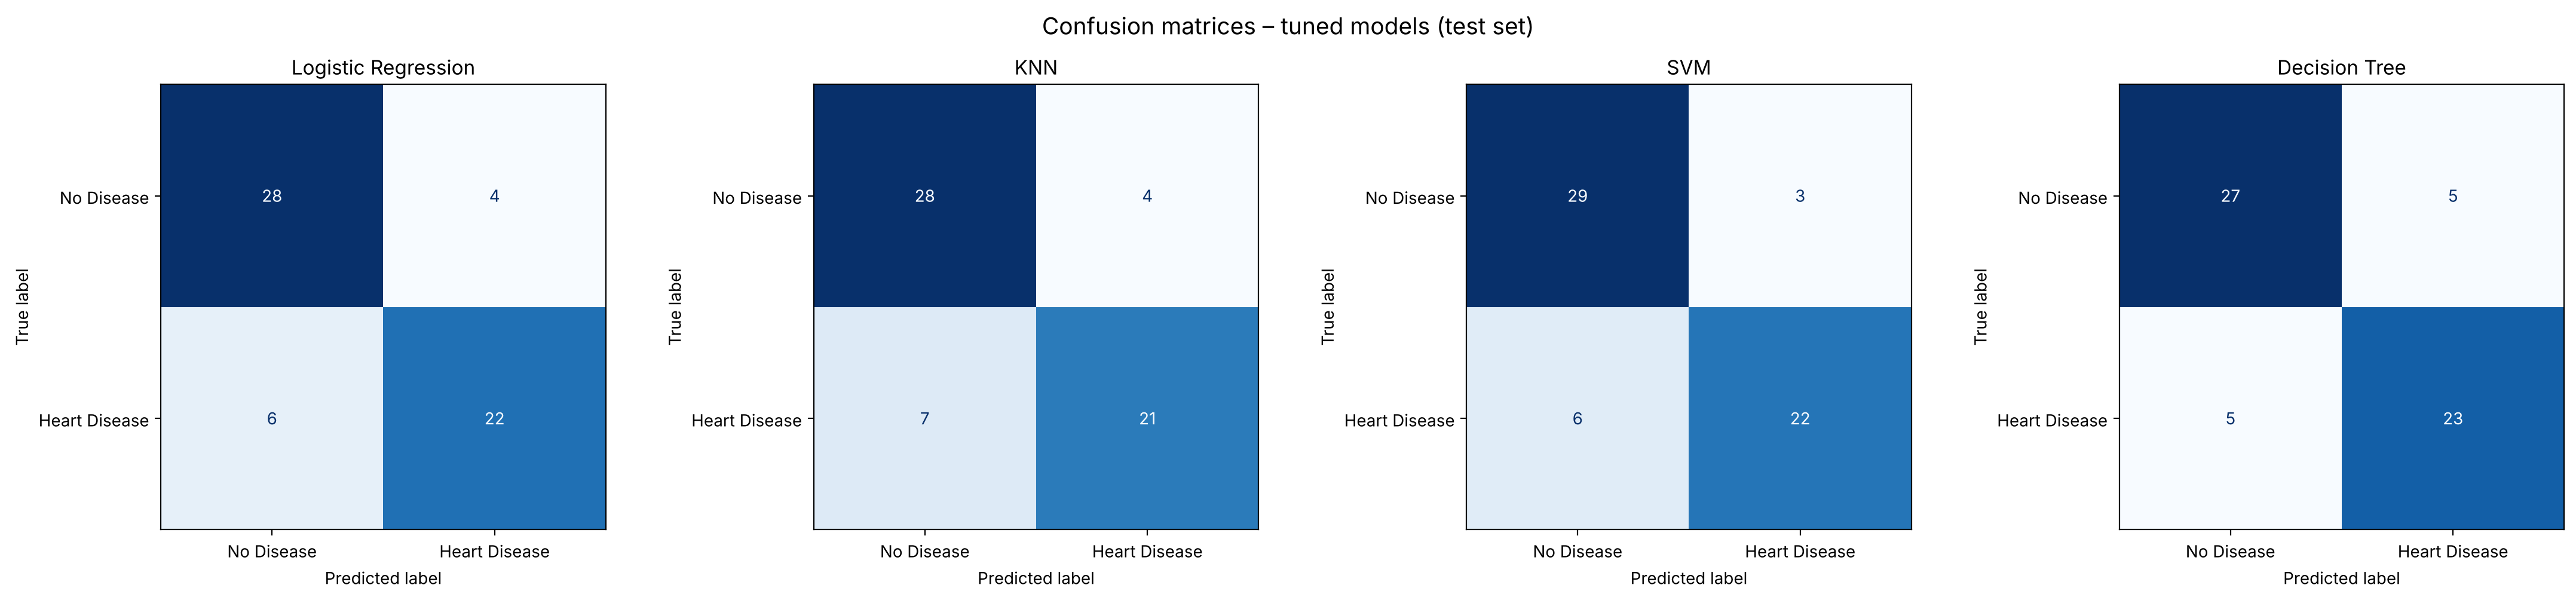

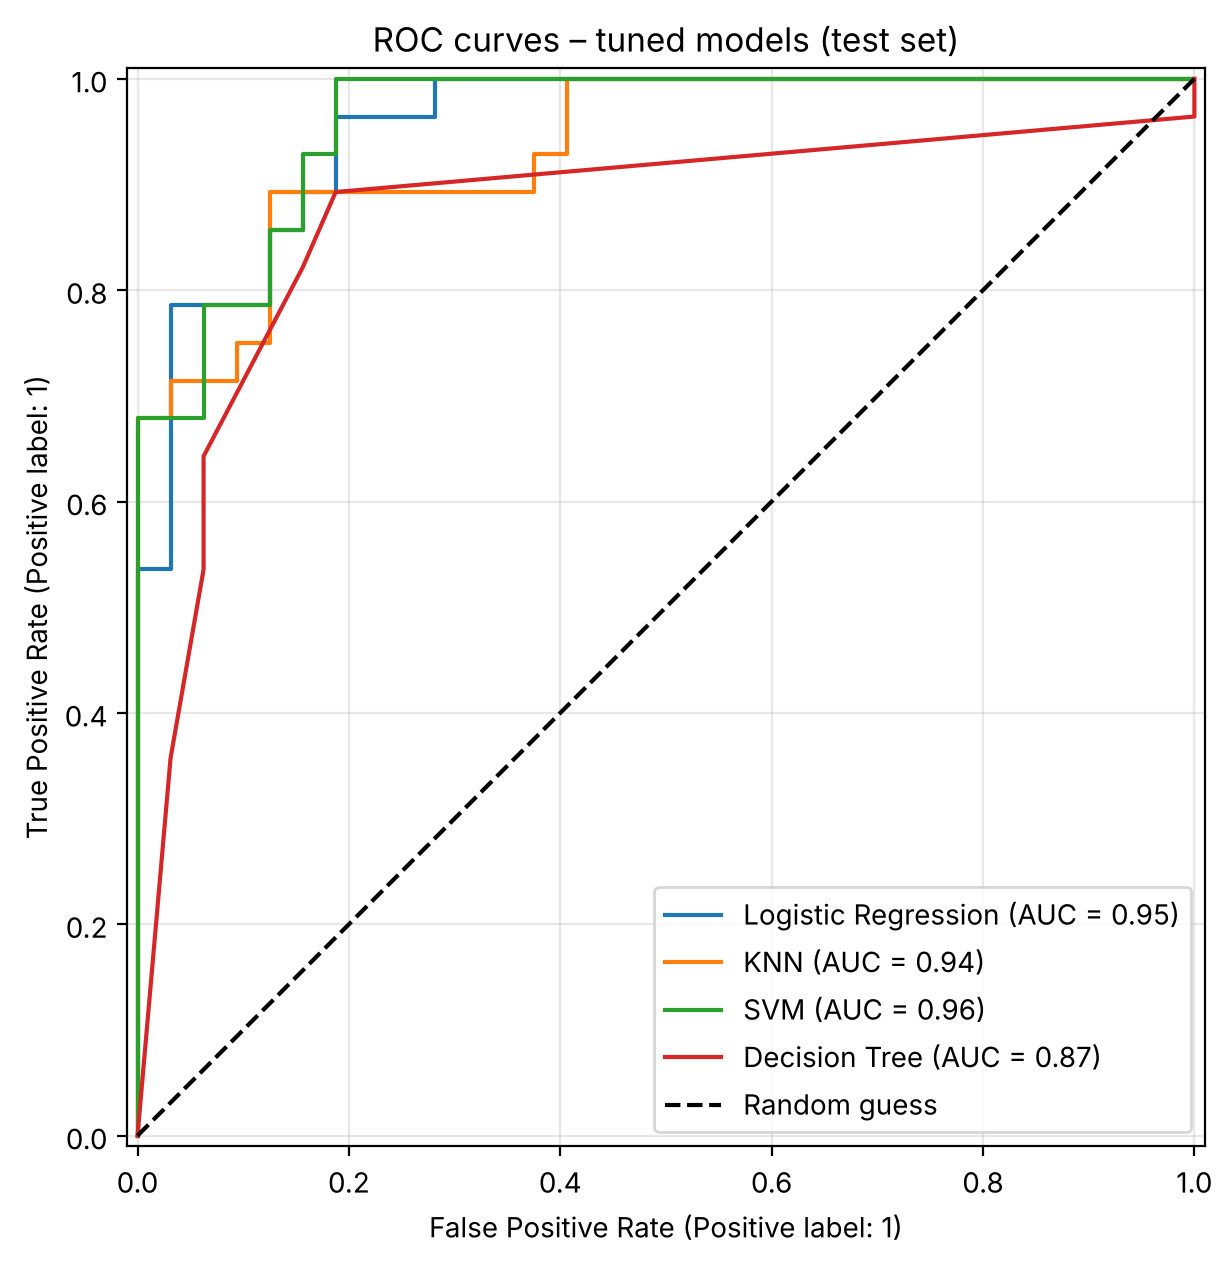

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (name, model) in zip(axes, tuned_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=["No Disease", "Heart Disease"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.suptitle("Confusion matrices – tuned models (test set)", fontsize=14)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
for name, model in tuned_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC curves – tuned models (test set)")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.show()

### 11.1 Test set findings
| Model | Accuracy | Recall | Specificity | ROC-AUC | Missed patients (FN) |
|---|---|---|---|---|---|
| Logistic Regression | 83.3% | 0.79 | 0.88 | 0.95 | 6 |
| KNN | 81.7% | 0.75 | 0.88 | 0.94 | 7 |
| **SVM** | **85.0%** | 0.79 | **0.91** | **0.96** | 6 |
| Decision Tree | 83.3% | **0.82** | 0.84 | 0.87 | **5** |

- **SVM (RBF, gamma = 0.001)** has the best overall balance: highest accuracy, specificity and ROC-AUC.
- **Decision Tree** has the highest recall (missed only 5 of the 28 sick patients), but the lowest ROC-AUC.
- The differences between the models are only **1–3 patients** out of 60, so **no model is clearly superior** on this test set.
- Interesting: the tuned KNN (K = 9) performed slightly worse on the test set than the paper's KNN (K = 7: 86.7% accuracy, recall 0.82). The choice made in cross-validation does not always transfer to a small test set.

## 12. Decision Tree Interpretation

The tuned Decision Tree is small, so its rules can be read directly. Feature importance shows which features reduce the Gini impurity the most. It describes how the model decides; it is not evidence of medical causation.

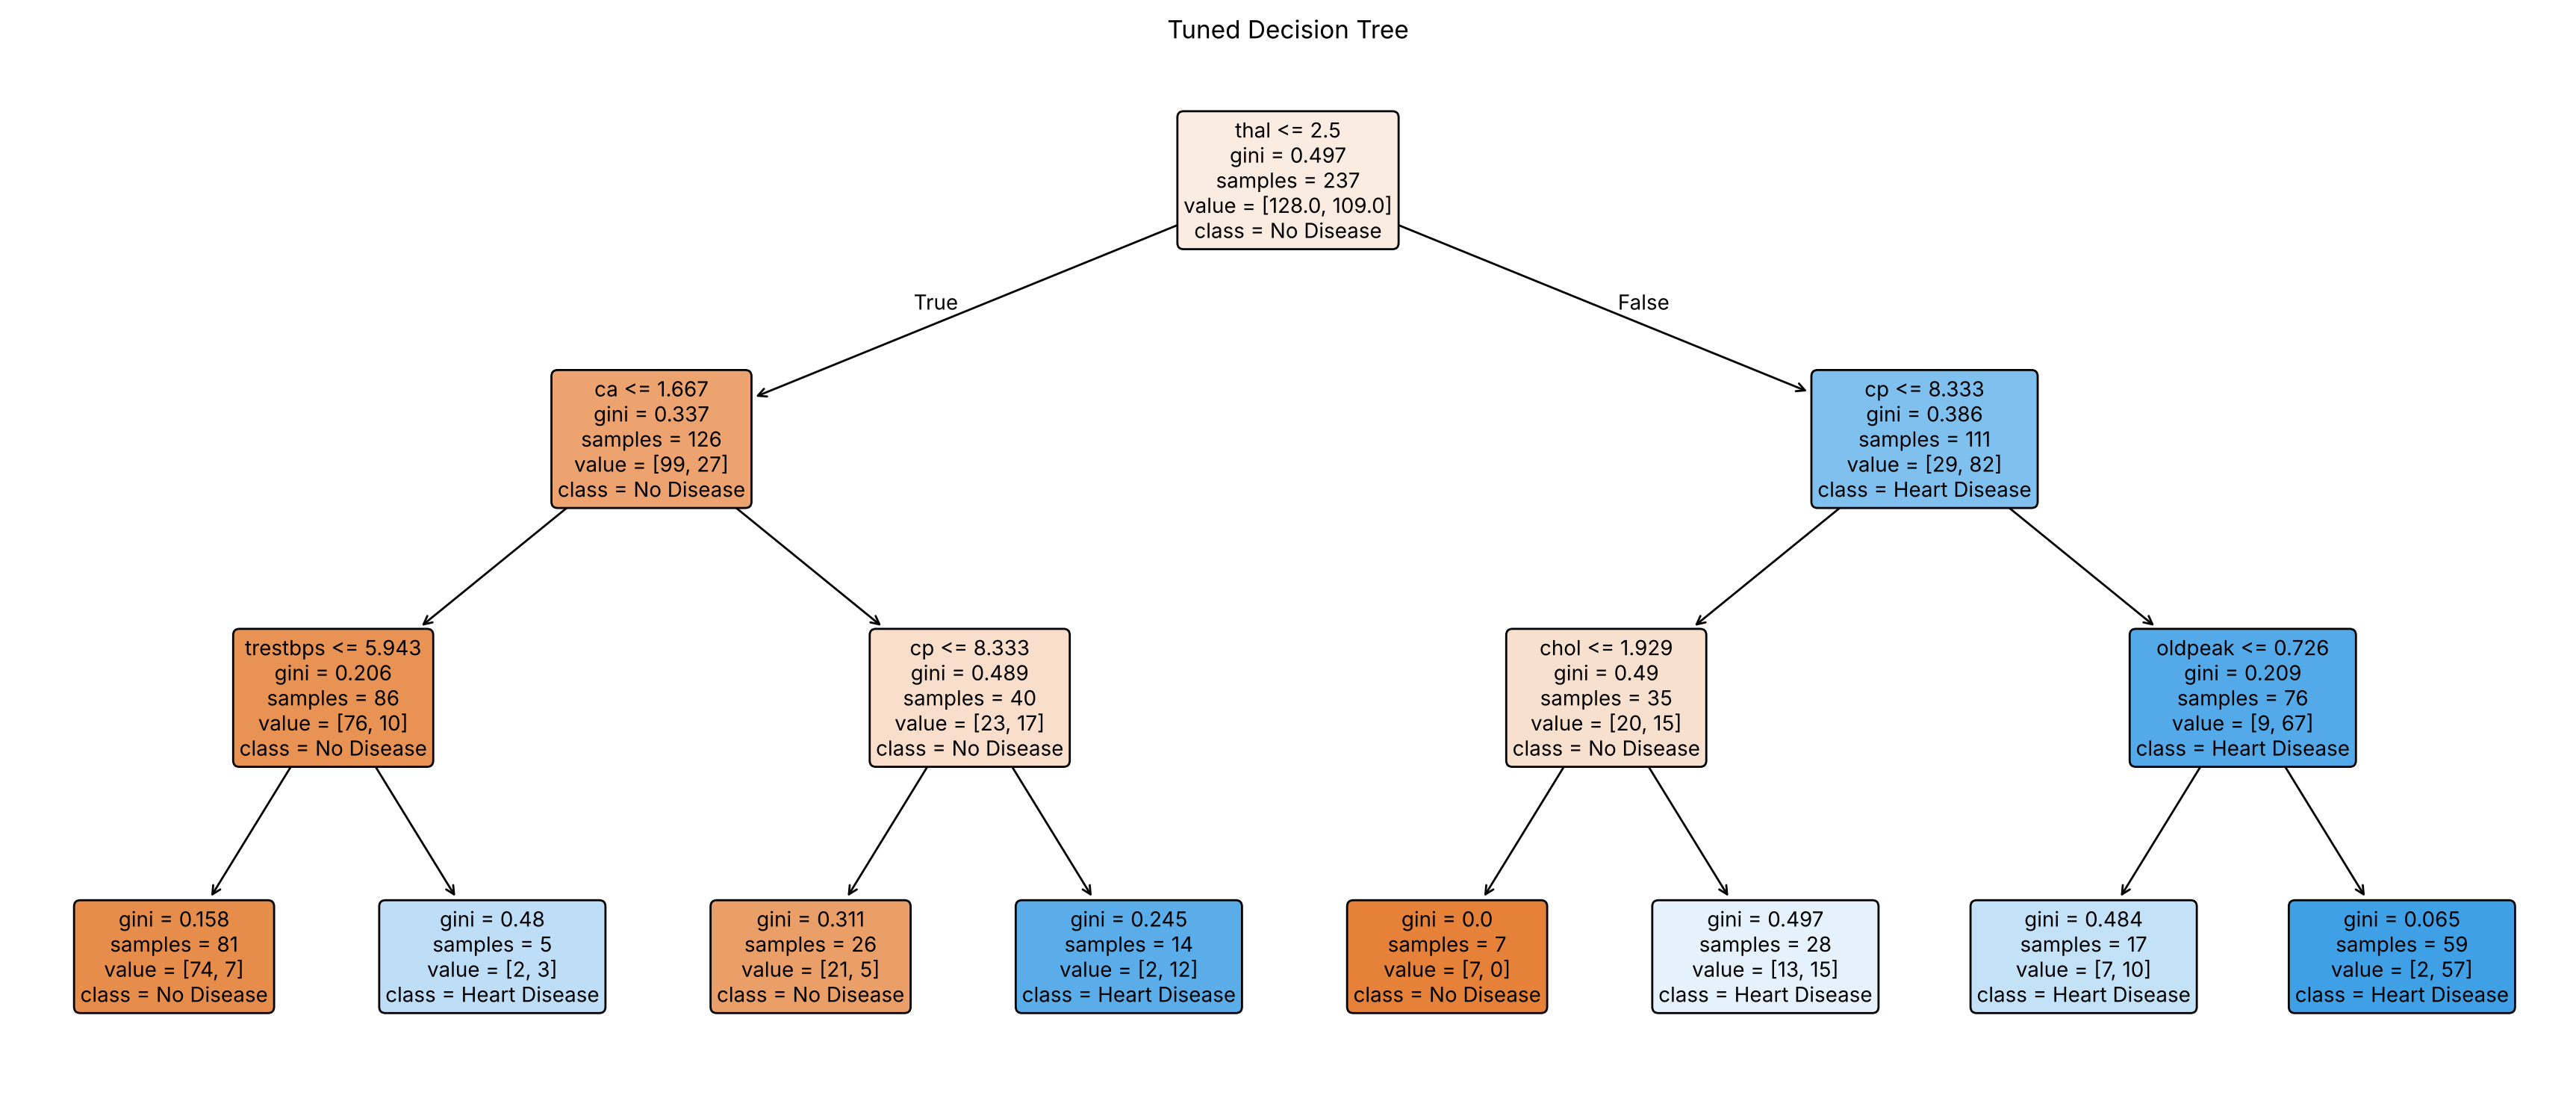

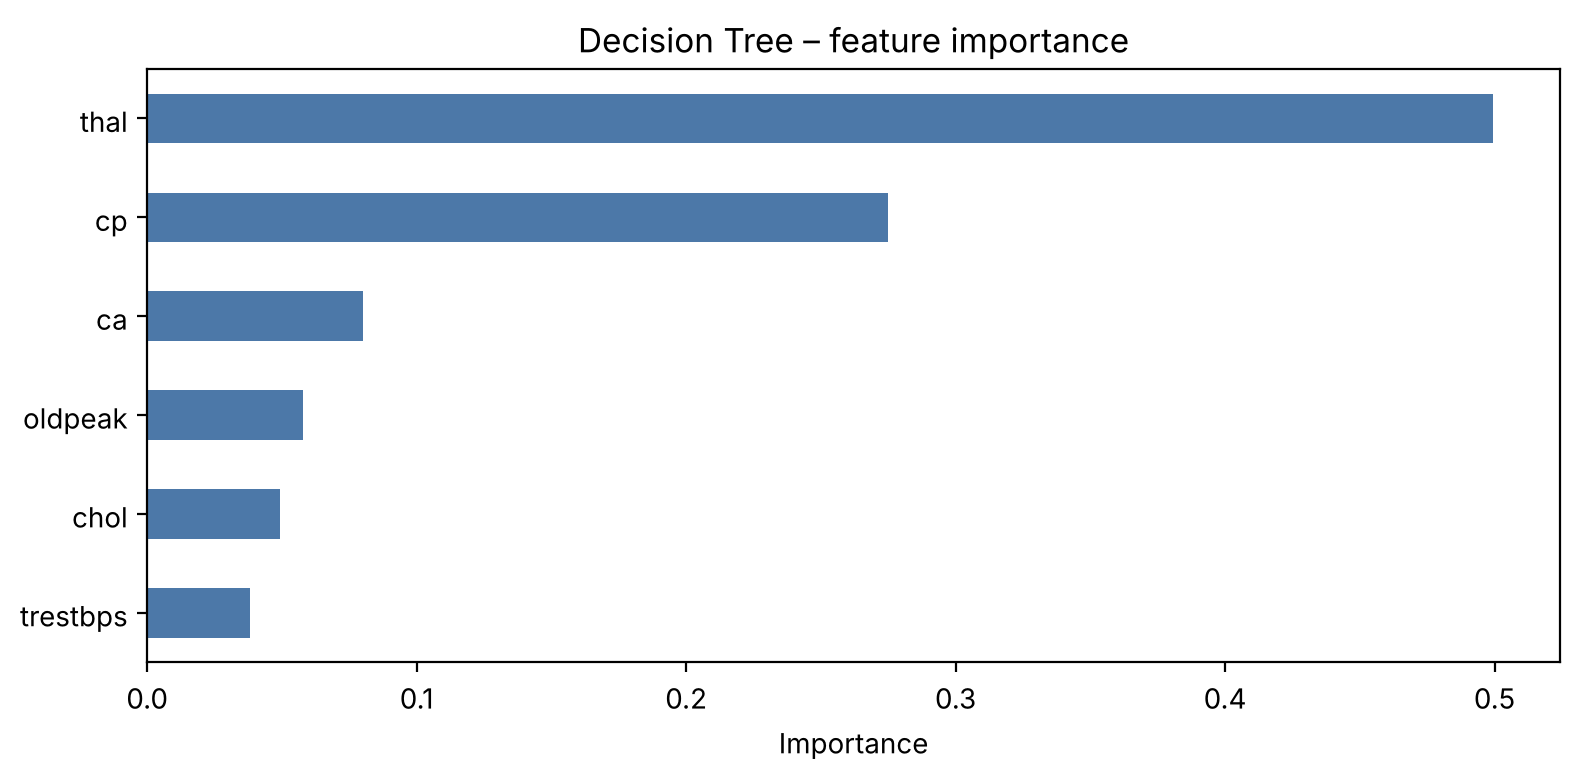

In [20]:
best_dt = tuned_models["Decision Tree"]
feature_names = best_dt.named_steps["encoder"].get_feature_names_out()

plt.figure(figsize=(22, 9))
plot_tree(best_dt.named_steps["model"], feature_names=feature_names,
          class_names=["No Disease", "Heart Disease"], filled=True,
          rounded=True, fontsize=10)
plt.title("Tuned Decision Tree")
plt.show()

importance = pd.Series(best_dt.named_steps["model"].feature_importances_,
                       index=feature_names).sort_values()
importance = importance[importance > 0]
importance.plot(kind="barh", figsize=(8, 4), color="#4C78A8",
                title="Decision Tree – feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

**Findings:**
- The tree uses only 3 levels, so its rules are easy to read. **Note:** the split thresholds are on the scaled (0–10) range. For example, `thal <= 2.5` means `thal` = normal (codes 3, 6, 7 → 0, 5, 10), and `cp <= 8.333` means the chest pain is *not* asymptomatic.
- The first split is **`thal`**, followed by **`ca`** and **`cp`**, which are also the features most correlated with heart disease in the EDA (Section 5.4).
- Example rule: patients with an abnormal `thal`, asymptomatic chest pain and `oldpeak` above the threshold are almost all classified as Heart Disease (57 of 59 in the training set).

## 13. Comparison with the Paper

Paper values come from the paper's Results section (accuracy and AUC from its summary; recall from its text).

,Paper accuracy,Paper ROC-AUC,Paper recall,Our accuracy (paper params),Our accuracy (tuned),Our ROC-AUC (tuned),Our recall (tuned)
Model,,,,,,,
Logistic Regression,0.869,0.92,0.84,0.833,0.833,0.954,0.786
KNN,0.885,0.92,0.72,0.867,0.817,0.935,0.750
SVM,0.869,0.93,0.84,0.533,0.850,0.960,0.786
Decision Tree,0.852,0.86,0.78,0.733,0.833,0.869,0.821


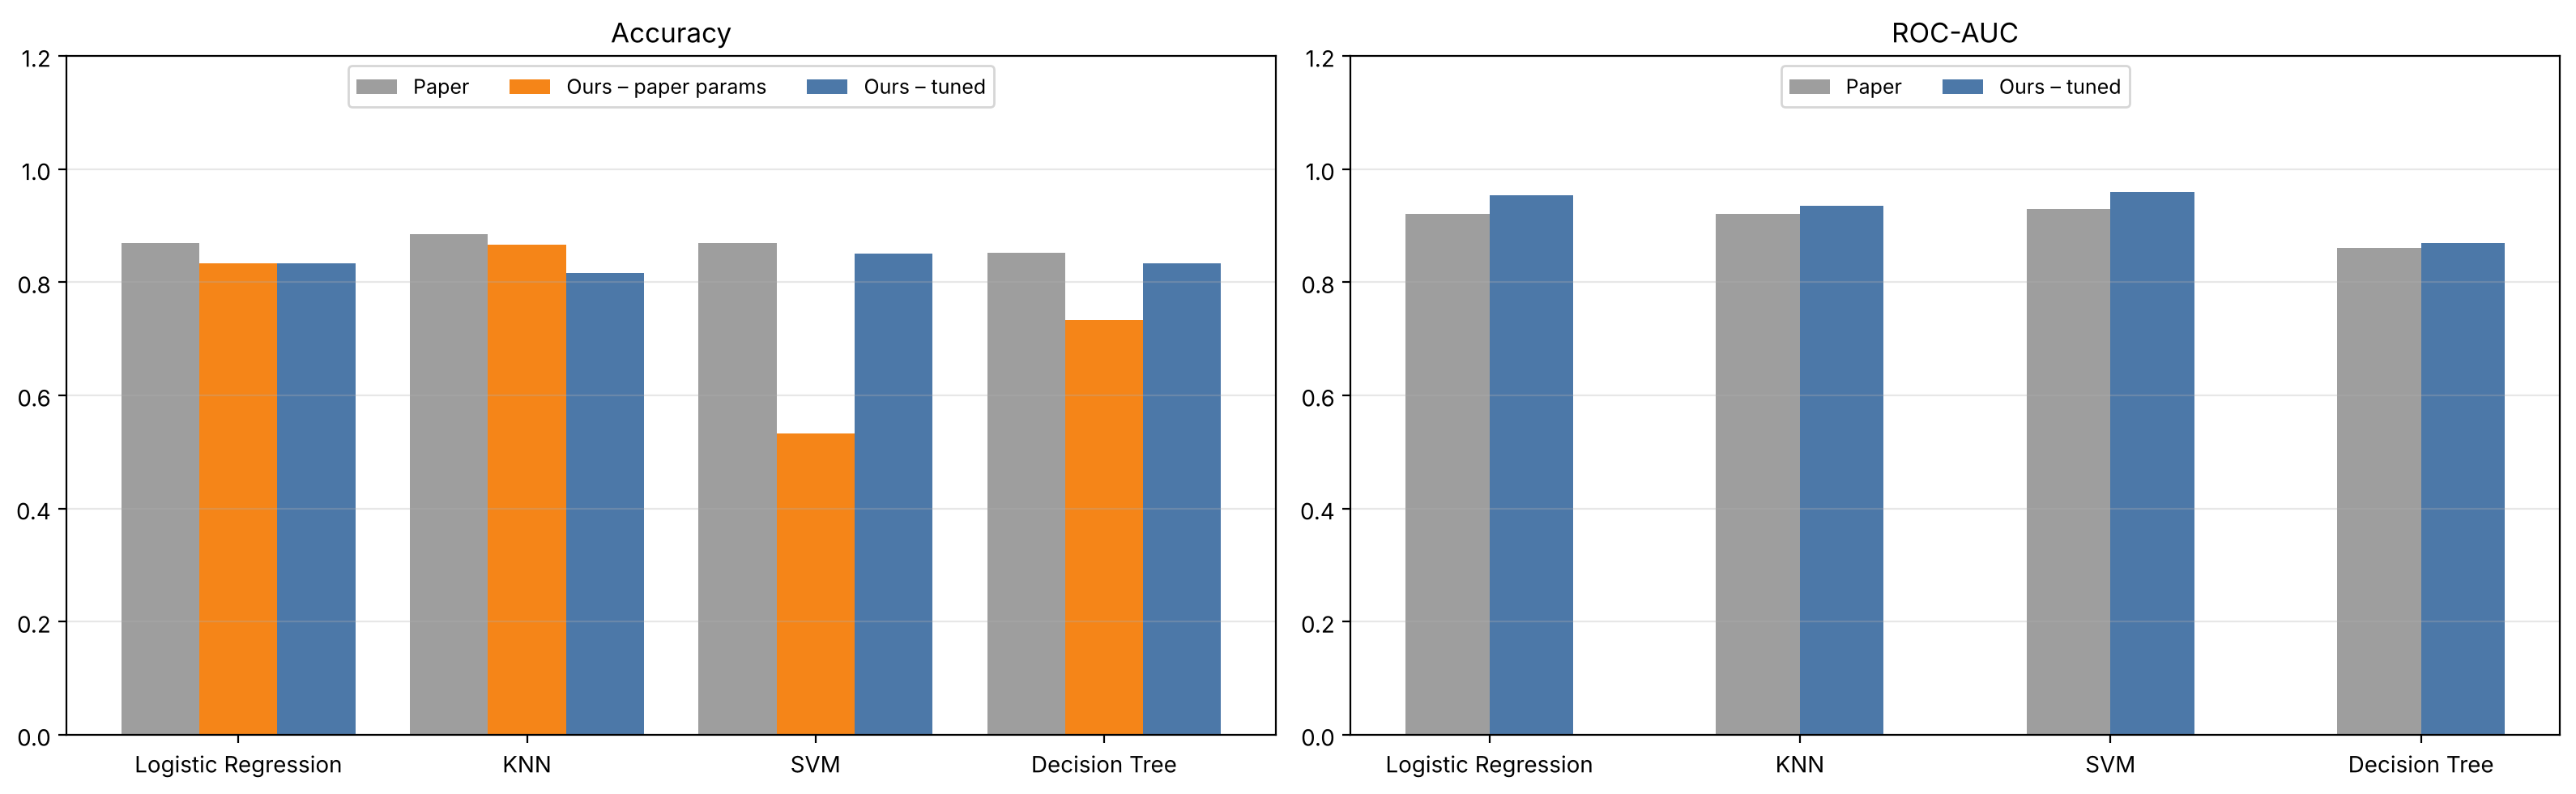

In [21]:
paper_reported = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "SVM", "Decision Tree"],
    "Paper accuracy": [0.8689, 0.8852, 0.8689, 0.8525],
    "Paper ROC-AUC": [0.92, 0.92, 0.93, 0.86],
    "Paper recall": [0.84, 0.72, 0.84, 0.78],
}).set_index("Model")

comparison = paper_reported.copy()
comparison["Our accuracy (paper params)"] = paper_results["Test accuracy"]
comparison["Our accuracy (tuned)"] = test_results["Accuracy"]
comparison["Our ROC-AUC (tuned)"] = test_results["ROC-AUC"]
comparison["Our recall (tuned)"] = test_results["Recall"]
display(comparison.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
x = np.arange(len(comparison))
w = 0.27
axes[0].bar(x - w, comparison["Paper accuracy"], w, label="Paper", color="#9e9e9e")
axes[0].bar(x, comparison["Our accuracy (paper params)"], w, label="Ours – paper params", color="#F58518")
axes[0].bar(x + w, comparison["Our accuracy (tuned)"], w, label="Ours – tuned", color="#4C78A8")
axes[0].set_title("Accuracy")
axes[1].bar(x - w / 2, comparison["Paper ROC-AUC"], w, label="Paper", color="#9e9e9e")
axes[1].bar(x + w / 2, comparison["Our ROC-AUC (tuned)"], w, label="Ours – tuned", color="#4C78A8")
axes[1].set_title("ROC-AUC")
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(comparison.index)
    ax.set_ylim(0, 1.2)
    ax.legend(loc="upper center", ncol=3, fontsize=9)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Findings:**
- **Accuracy:** our tuned models reached 82–85%, slightly below the paper (85–89%). With the paper's hyperparameters, Logistic Regression and KNN were close to the paper, while SVM and Decision Tree were much lower.
- **ROC-AUC:** our tuned models reached 0.87–0.96, **slightly higher** than the paper (0.86–0.93).
- **Recall:** ours is similar to the paper (0.75–0.82 vs 0.72–0.84).
- Because the split, the `random_state` and some preprocessing details are not reported in the paper, this is an **approximate reproduction**, not an exact replication. The overall level of performance is consistent with the paper.

## 14. Issues Found in the Paper

1. **Swapped hyperparameter labels:** the KNN and SVM hyperparameters are listed under the wrong model names.
2. **SVM hyperparameters do not match the described scaling:** `gamma = 0.65` with features scaled to (0, 10) makes the RBF kernel almost zero (Section 9). Either the scaling or the `gamma` reported is not the one actually used.
3. **Inconsistent numbers:** for example, Decision Tree AUC is 0.88 in the text but 0.86 in the summary table; KNN AUC is 0.91 in one paragraph and 0.92 in another; the summary table source says "2022" while the rest of the paper says "2025".
4. **Missing methodology details:** the paper does not report the train/test split `random_state`, whether the split was stratified, or whether scaling was done before or after the split.
5. **Missing data details:** the paper does not report how many patients remained after cleaning or the class distribution.

## 15. Suggested Improvements

1. **One-hot encoding** for `cp`, `restecg`, `slope` and `thal`: these categories have no natural order, so ordinal codes can mislead distance-based models (KNN, SVM).
2. **Standard (0, 1) scaling** instead of (0, 10), which works with the default SVM settings.
3. **Repeated or nested cross-validation** for the final comparison, instead of a single 60-patient test set, to get more stable results.
4. **Threshold tuning:** lowering the decision threshold could increase recall (fewer missed patients) at the cost of more false alarms, which is acceptable for screening.
5. **More data:** the dataset is small (297 patients) and old (1988). Combining it with the other UCI hospitals (Hungary, Switzerland, VA Long Beach) could improve generalization.
6. **Report the full methodology** (split, `random_state`, scaling order) so the study can be reproduced exactly.

## 16. Conclusions and Limitations
### Conclusions
1. **The paper's results were approximately reproduced.** Logistic Regression and KNN with the paper's hyperparameters reached 83–87% accuracy (paper: 87–89%), and all tuned models reached a ROC-AUC between 0.87 and 0.96 (paper: 0.86–0.93).
2. **The paper's SVM hyperparameters do not work with the scaling it describes.** With `gamma = 0.65` and features in (0, 10), the SVM predicted almost every patient as healthy (recall 0.04). After tuning (`gamma = 0.001`), it became the model with the best overall balance (85.0% accuracy, ROC-AUC 0.96, specificity 0.91).
3. **Hyperparameter tuning reduced overfitting**, especially for the Decision Tree (depth limited to 3) and the SVM.
4. **Recommended model: SVM (RBF, C = 10, gamma = 0.001).** It had the best overall balance on the test set: highest accuracy (85.0%), specificity (0.91) and ROC-AUC (0.96), with the same recall as Logistic Regression (0.79). The Decision Tree had the highest recall (0.82), but it won by only one patient (5 vs 6 missed patients) and had the lowest ROC-AUC (0.87). Logistic Regression is a good alternative when interpretability is the priority (ROC-AUC 0.95).
5. **The differences between models are small.** The four tuned models differ by only 1–3 patients on the 60-patient test set, so the recommendation above should be confirmed with more data (for example, repeated cross-validation or an external dataset).
6. The most important features were **`thal`, `ca`, `cp`, `oldpeak`, `exang` and `thalach`**, consistent with the correlation analysis in the EDA (Section 5.4).

### Limitations
- **Small dataset:** 297 patients after cleaning; the test set has only 60 patients (28 with heart disease), so each error changes recall by about 3.6 percentage points.
- **Old and not diverse data:** collected in 1988 at a single hospital, with about 68% male patients.
- **Approximate reproduction:** the paper does not report its split, `random_state` or scaling order.
- Random Forest and Gradient Boosting from the paper were not implemented (not covered in class yet).
- These results are **not clinically validated** and should not be used for real diagnosis.